# Modeling a Galaxy with The Tractor

This notebook demonstrates how The Tractor (Lang et al. 2016) works on a single source in a Euclid VIS
image. The Tractor measures sources with a generative model: it takes a parameterized source model
together with the image's point-spread function (PSF), noise, sky level, and zeropoint, renders the
predicted image, and adjusts the parameters until the model best matches the data (for
independent Gaussian noise, minimum chi-squared). Forced photometry follows directly: a model fitted in
one band is held fixed in position and shape and refitted only for flux in the other bands, so every
band is measured with the same source model, even where a source is faint, blended, or undetected.
The notebooks that follow extend this to whole catalogs and to other instruments.


## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import euclid_phot as ep
from tractor import (Image, PixelizedPSF, ConstantSky, LinearPhotoCal, NullWCS,
                     PixPos, Flux, EllipseE, ExpGalaxy, Tractor)

# Coordinates of the galaxy (degrees) and the side of the square cutout (arcsec).
# Any position inside the Euclid footprint works; the image is fetched from IRSA.
RA, DEC = 269.45284, 67.28963
SIZE = 6.0

## 1. Load the VIS cutout and its PSF

``fetch_cutout`` reads a ``SIZE`` arcsec box out of the MER VIS mosaic together with the matching
RMS map, which gives the noise in each pixel.

MER provides a PSF model evaluated at the position of every catalog source, the CATALOG-PSF
product. ``extract_catalog_psf`` returns the stamps around the target, and ``get_psf_for_source``
selects the one closest to the galaxy.

The cutout and the PSF stamps are downloaded from IRSA on first use and read from the local cache
afterwards.

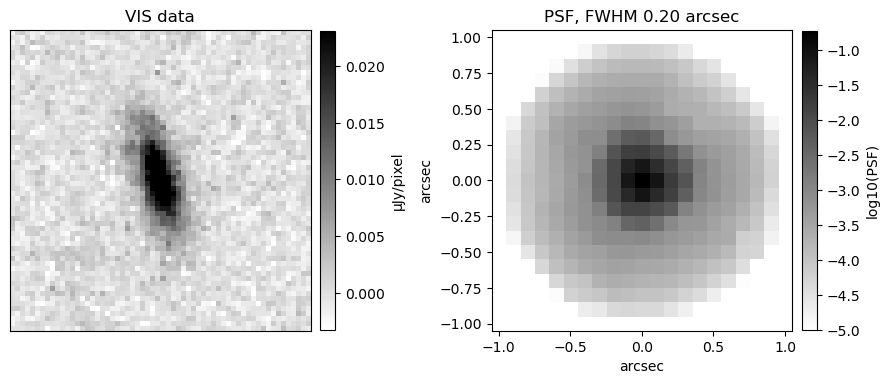

In [2]:
vis = ep.fetch_cutout("VIS", RA, DEC, SIZE)
psf_data = ep.extract_catalog_psf("VIS", RA, DEC, tile_id=vis.header.get("MERTILE"))
psf, psf_fwhm, _ = ep.get_psf_for_source(psf_data, RA, DEC)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
ep.viz.show_cutout(vis, ax=ax1, title="VIS data")

psf_half = psf.shape[0] / 2 * vis.pixel_scale_arcsec
ax2.imshow(np.log10(np.clip(psf, 1e-5, None)), origin="lower", cmap="gray_r",
           extent=[-psf_half, psf_half, -psf_half, psf_half])
ep.viz.add_colorbar(ax2, label="log10(PSF)")
ax2.set_title(f"PSF, FWHM {psf_fwhm:.2f} arcsec")
ax2.set_xlabel("arcsec")
ax2.set_ylabel("arcsec")
plt.tight_layout()
plt.show()


## 2. Construct the Tractor image and the source model

The fit is specified by three objects.

An ``Image`` contains the pixel data, the inverse variance, the PSF, the sky model, and the
magnitude zeropoint, taken from the ``MAGZERO`` header keyword. Converting it to image units per
microJansky and passing that to ``LinearPhotoCal`` makes the fitted amplitude a flux in microJansky.

We choose an exponential profile, ``ExpGalaxy``, as the source model: this galaxy is a disk, and
it is the simplest resolved profile The Tractor offers. Later notebooks instead select the profile per
source by comparing several. The model is parameterized by position, flux, and shape. The shape is
stored as a half-light radius and two ellipticity components, equivalently as an axis ratio and a
position angle. The position is held fixed at the catalog coordinate, which
is the sense in which the photometry is forced. The remaining parameters are initialized away from
the expected solution, at 2 microJansky, circular, and compact.

The ``Tractor`` object combines the image and the source model and performs the optimization.

In [3]:
data = vis.data
invvar = 1.0 / vis.rms**2
x, y = vis.wcs.all_world2pix(RA, DEC, 0)

counts_per_ujy = 10 ** (0.4 * (vis.header["MAGZERO"] - 23.9))
tim = Image(data=data, invvar=invvar, psf=PixelizedPSF(psf),
            wcs=NullWCS(pixscale=vis.pixel_scale_arcsec),
            sky=ConstantSky(0.0), photocal=LinearPhotoCal(counts_per_ujy))

gal = ExpGalaxy(PixPos(float(x), float(y)), Flux(2.0), EllipseE.fromRAbPhi(0.15, 1.0, 0.0))
gal.freezeParam("pos")

tractor = Tractor([tim], [gal])
tractor.freezeParam("images")

## 3. Optimize the model against the pixels

Each call to ``optimize`` performs one step. The Tractor computes the derivative of the predicted
image with respect to each free parameter, solves the resulting linear least-squares problem for the
direction that most reduces chi-squared, evaluates a set of step lengths along that direction, and
retains the best step. Four parameters vary here: the flux and the three shape parameters.

The loop below prints the parameters after each step and stops when the gain in
log-likelihood is below `1e-3`, or after 30 steps. This is a numerical stopping
criterion; it does not establish that the profile fully describes the galaxy.

In [4]:
for step in range(30):
    dlnp, _, _ = tractor.optimize()
    print(f"step {step + 1}: flux {gal.brightness.getValue():.2f} uJy, "
          f"re {gal.shape.re:.2f} arcsec, b/a {gal.shape.ab:.2f}")
    if dlnp < 1e-3:
        break

step 1: flux 2.05 uJy, re 0.44 arcsec, b/a 0.11
step 2: flux 2.72 uJy, re 0.73 arcsec, b/a 0.33
step 3: flux 4.07 uJy, re 0.98 arcsec, b/a 0.27
step 4: flux 4.08 uJy, re 0.91 arcsec, b/a 0.30
step 5: flux 4.10 uJy, re 0.92 arcsec, b/a 0.30
step 6: flux 4.10 uJy, re 0.92 arcsec, b/a 0.30
step 7: flux 4.10 uJy, re 0.92 arcsec, b/a 0.30


## 4. Data, model, and residual

Below we plot the galaxy, the best-fit model, and their residual. The third panel is the chi image:
the residual, data minus model, divided by the noise sigma of each pixel. This is the quantity
returned by ``Tractor.getChiImage``, and its sum of squares is the chi-squared minimized by the fit.
Coherent residual structure can reveal limitations of the profile, PSF, or background even after
numerical convergence.

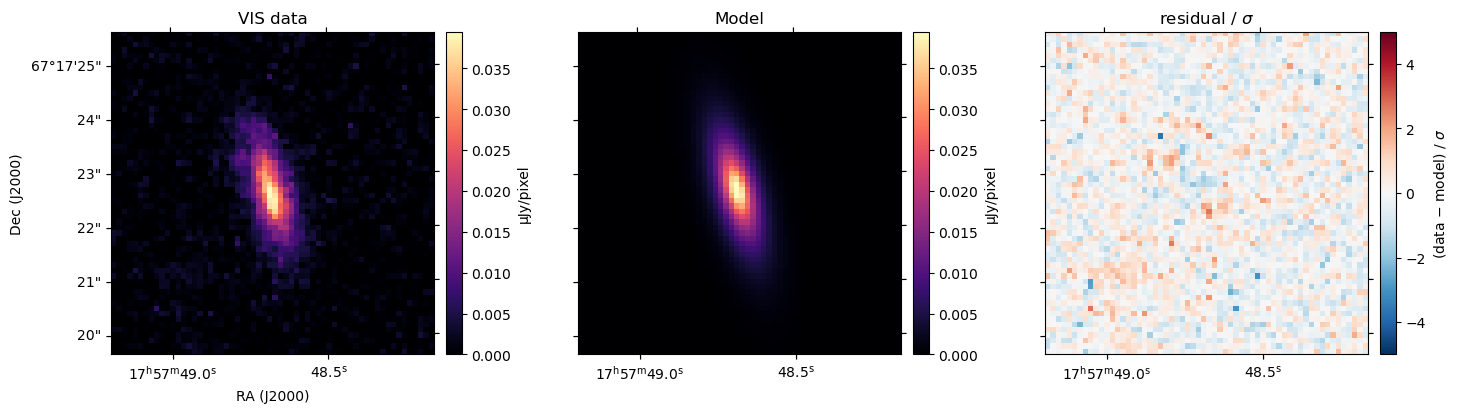

In [5]:
model = tractor.getModelImage(0)
chi = (data - model) * np.sqrt(invvar)
UJY = ep.viz.ujy_per_unit(vis)  # microJansky per image unit, from MAGZERO

vmax = 0.85 * data.max() * UJY
panels = [(data * UJY, "VIS data", "µJy/pixel", dict(cmap="magma", vmin=0, vmax=vmax)),
          (model * UJY, "Model", "µJy/pixel", dict(cmap="magma", vmin=0, vmax=vmax)),
          (chi, r"residual / $\sigma$", r"(data $-$ model) / $\sigma$", dict(cmap="RdBu_r", vmin=-5, vmax=5))]

fig = plt.figure(figsize=(15, 4.2))
for k, (img, title, unit, kw) in enumerate(panels):
    ax = fig.add_subplot(1, 3, k + 1, projection=vis.wcs)
    im = ax.imshow(img, origin="lower", **kw)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label=unit)
    ax.set_title(title)
    ax.coords[0].set_ticks(number=3)
    if k == 0:
        ax.set_xlabel("RA (J2000)")
        ax.set_ylabel("Dec (J2000)")
    else:
        ax.coords[0].set_axislabel("")
        ax.coords[1].set_axislabel("")
        ax.coords[1].set_ticklabel_visible(False)
plt.tight_layout()
plt.show()